In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np
import cv2 



In [3]:
img_height, img_width = 150,150
batch_size = 32 

train_dir = 'train'         
test_dir = 'test'


In [4]:
train_datagen = ImageDataGenerator(rescale=1.0/255)
test_datagen = ImageDataGenerator(rescale=1.0/255)

train_gen = train_datagen.flow_from_directory(train_dir,target_size=(img_height,img_width),batch_size=batch_size,class_mode='binary')

test_gen = test_datagen.flow_from_directory(test_dir,target_size=(img_height,img_width),batch_size=batch_size,class_mode='binary')



Found 2000 images belonging to 2 classes.
Found 10 images belonging to 2 classes.


In [5]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(img_height, img_width, 3)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')  # Binary output
])

c:\College-projects\Semester 9\DPS920\a2\q2\cat-dog-prediction\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
# 3. Compile
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 4. Train
history = model.fit(
    train_gen,
    epochs=20,
    validation_data=test_gen
)

# 5. Save the model
model.save('cat_dog_cnn.h5')

c:\College-projects\Semester 9\DPS920\a2\q2\cat-dog-prediction\.venv\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 237ms/step - accuracy: 0.4985 - loss: 0.8474 - val_accuracy: 0.7000 - val_loss: 0.6731
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 220ms/step - accuracy: 0.6010 - loss: 0.6759 - val_accuracy: 0.7000 - val_loss: 0.5726
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 227ms/step - accuracy: 0.6636 - loss: 0.6117 - val_accuracy: 0.7000 - val_loss: 0.4822
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 239ms/step - accuracy: 0.7382 - loss: 0.5512 - val_accuracy: 0.9000 - val_loss: 0.4223
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 226ms/step - accuracy: 0.7488 - loss: 0.5139 - val_accuracy: 0.6000 - val_loss: 0.5436
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 238ms/step - accuracy: 0.8054 - loss: 0.4272 - val_accuracy: 0.7000 - val_loss: 0.6074
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 234ms/step - accuracy: 0.8397 - loss: 0.3594 - val_accuracy: 0.8000 - val_loss: 0.4813
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 233ms/step - accuracy: 0.8918 - loss: 0.2669 - val_accu

In [14]:
def predict_cat_or_dog(img_path, model_path='cat_dog_cnn.h5'):
    
    model = tf.keras.models.load_model(model_path)
    
    
    img = image.load_img(img_path, target_size=(150, 150))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    demo=cv2.imread(img_path)
    demo=cv2.cvtColor(demo,cv2.COLOR_BGR2RGB)
    plt.imshow(demo.astype("uint8"))
    plt.axis('off')
    plt.title("Input Image")
    plt.show()

    
    prediction = model.predict(img_array)
    result = "Dog" if prediction[0][0] > 0.5 else "Cat"
    print(f"Prediction: {result}")

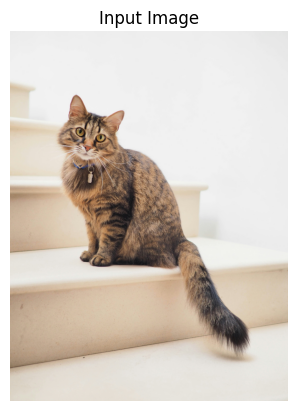

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


Prediction: Cat


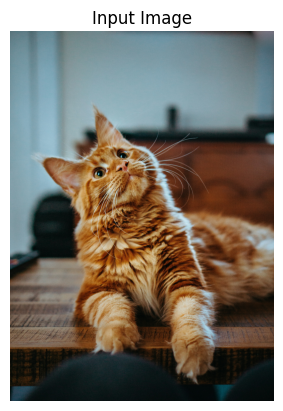

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


Prediction: Dog


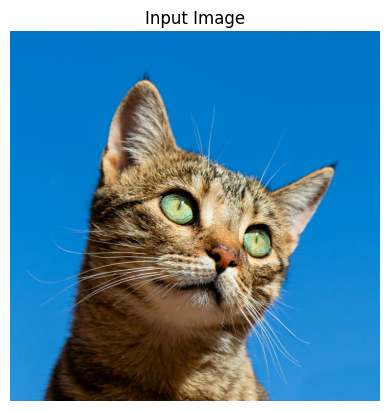

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


Prediction: Cat


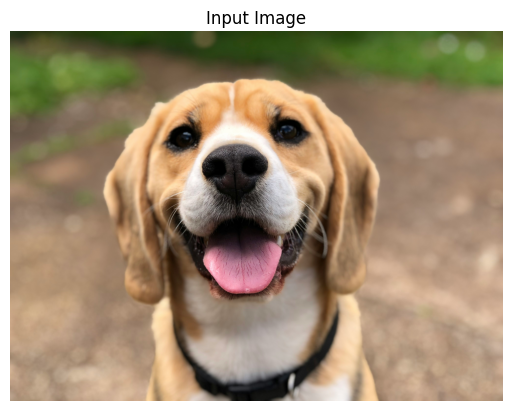

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


Prediction: Dog


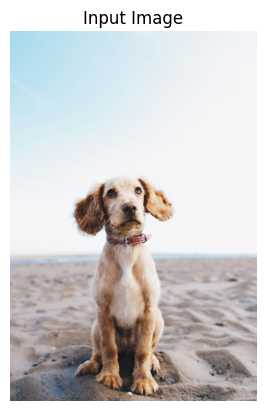

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


Prediction: Dog


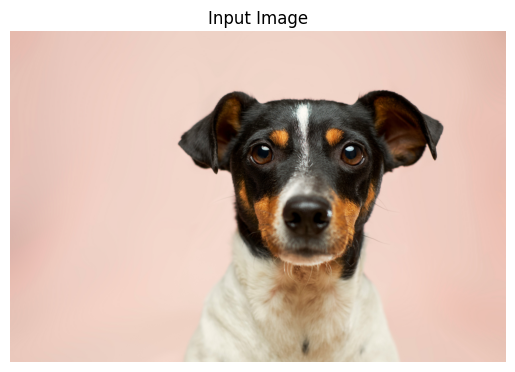

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
Prediction: Dog


In [15]:
predict_cat_or_dog('cat1.jpg')
predict_cat_or_dog('cat2.jpg')
predict_cat_or_dog('cat3.jpg')
predict_cat_or_dog('dog1.jpg')
predict_cat_or_dog('dog2.jpg')
predict_cat_or_dog('dog3.jpg')